# 04 · RPI test, feature library and protocol freeze (Day 2: Stage-0 verdict + Stages 2–3)
**Microstructure Alpha · Binance USD-M ETHUSDT perpetual · 7–14 Sep 2026**

| Section | What it does |
|---|---|
| 0 | **RPI test and Stage-0 verdict.** Are trades that are unexplained while the book is still consistent with fills against **RPI (Retail Price Improvement) orders**, which Binance excludes from the standard depth stream? |
| 1 | **Feature library on two clocks**: a 100 ms grid on **exchange time** (research) and on **received time** (trading decisions), stored per day |
| 2 | Feature sanity (feature distributions only, **no target relationships before the freeze**) |
| 3 | **Protocol freeze**: data split, hypotheses H1–H7, purge rules, inference settings and cost assumptions written to `protocol/protocol.json` with a SHA-256 hash. Every later notebook calls `ma_lib.load_protocol()` and refuses to run if the file changed |

### Why RPI
Binance's API docs say RPI orders "are not visible and excluded" from the standard order book, while the separate RPI book "includes" them and hides crossed price levels. RPI orders launched on Binance futures on 20 Nov 2025 and match only **non-algorithmic** taker orders. A hidden RPI sell resting at or below the visible best bid, filled by a retail buy, would print on the **wrong side** of the book we see, with **no visible depth change**. That is the pattern this section tests.

**Criteria (fixed before running).** QU = trades unexplained in notebook 02 that occur in a batch where the mid moved ≤ 1 tick.
- **R1:** ≥ 70% of QU are `wrong_side` or `inside_spread`, i.e. better than the visible book.
- **R2:** ≥ 80% of QU improve on the visible book by **1–3 ticks**. RPI improves the price slightly; changes inside a batch can be dozens of ticks away.
- **R3:** ≤ 20% of QU coincide with a visible drop of the touch queue at least as large as the trade.

Each must hold pooled across all days **and** on at least 6 of 8 days. Single-fill share and trade size are reported but not used for the verdict.

In [1]:
# ===================== CONFIG — same paths as before =====================
from pathlib import Path
OUT_DIR    = Path(r"C:\microalpha_proj\microoutput")
DATES      = [f"2026-09-{d:02d}" for d in range(7, 15)]   # days to process
ALL_DATES  = [f"2026-09-{d:02d}" for d in range(7, 15)]   # the study's 8 days (used by the protocol; do not edit)
BIN_MS     = 100           # feature grid resolution
LAT_BAD_MS = 1000          # received-clock bins with feed latency above this are flagged
STALE_MS   = 1000          # received-clock bins whose latest book state is older than this are flagged
R1_MIN, R2_MIN, R3_MAX, DAYS_MIN = 0.70, 0.80, 0.20, 6
STRICT     = True
# ==========================================================================

In [2]:
import sys, time, json, numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, str(Path.cwd()))
import ma_lib
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 60)
REP, BOOK, TRD, EVT, FEA, PRO = (OUT_DIR / x for x in ('reports', 'book', 'trades', 'events', 'features', 'protocol'))
for d in (FEA / 'ex', FEA / 'rx', PRO): d.mkdir(parents=True, exist_ok=True)
need = [EVT / f'taker_orders_{d}.parquet' for d in DATES] + [TRD / f'trades_{d}.parquet' for d in DATES]
need += [EVT / d / f'events_{d}_{h:02d}.parquet' for d in DATES for h in range(24)]
miss = [str(p.name) for p in need if not p.exists()]
print('missing inputs:', miss[:10] or 'none')
if STRICT and miss: raise RuntimeError('run notebooks 01–03 first')

missing inputs: none


## 1 · Main pass: RPI diagnostics, trade flags and the feature grid
For each hour this pass:
1. Computes, for every usable trade, the batch's |Δmid|, the price improvement relative to the visible book, and whether the visible touch queue fell by at least the trade size.
2. Flags `rpi = True` for QU trades (unexplained, and the mid moved ≤ 1 tick).
3. Builds one row per batch and aggregates the rows onto the 100 ms grid on both clocks.

**Grid conventions.** `t_end` is the end of the bin, i.e. the decision time. Flows are summed over the bin; states are the last batch known by `t_end`, forward-filled across bins and hours. On the received clock, a batch belongs to the bin of its **received** time, and trades inherit their batch's received time (trades carry no receive stamp of their own). Validity: `valid_ex` = state ok and no invalid batch in the bin; `valid_rx` additionally needs latency ≤ `LAT_BAD_MS` and state age ≤ `STALE_MS`.

In [3]:
t_start = time.time()
diag_days, size_samples, fstats = [], [], []
prev_tail, ps_x, ps_r, left_r = None, None, None, None
rng = np.random.default_rng(7)
for date in DATES:
    t0 = time.time()
    trd = pd.read_parquet(TRD / f'trades_{date}.parquet')
    trd['n_fills'] = ma_lib.order_size_per_trade(trd)
    trd['rpi'] = False; trd['dmid'] = np.nan; trd['improve_ticks'] = np.nan
    orders = pd.read_parquet(EVT / f'taker_orders_{date}.parquet')
    orders = orders[orders.u_post >= 0].sort_values('u_post', kind='stable').reset_index(drop=True)   # lookup needs sorted u_post
    up = trd.u_post.to_numpy(); oup = orders.u_post.to_numpy()
    tro = np.argsort(up, kind='stable'); ups = up[tro]
    D = dict(date=date, qu=0, qu_wrong_or_inside=0, qu_impr_1_3=0, qu_drop_covers=0, qu_single=0,
             ctl=0, ctl_drop_covers=0, ctl_single=0); impr_hist = {}
    gx_list, gr_list = [], []
    day_t0 = int(pd.Timestamp(date).value // 10**6)
    for hour in range(24):
        epath = EVT / date / f'events_{date}_{hour:02d}.parquet'
        if not epath.exists(): prev_tail = None; continue
        book = pd.read_parquet(BOOK / date / f'book_{date}_{hour:02d}.parquet')
        ev = pd.read_parquet(epath)
        lo, hi = np.searchsorted(ups, book.u.iloc[0], 'left'), np.searchsorted(ups, book.u.iloc[-1], 'right')
        idx = tro[lo:hi]; trh = trd.iloc[idx]
        use_m = trh.cls.to_numpy() >= 0
        if use_m.any():
            dg = ma_lib.rpi_diag_hour(book, prev_tail, trh[use_m])
            ui = idx[use_m]
            trd.iloc[ui, trd.columns.get_loc('dmid')] = dg.dmid.to_numpy()
            trd.iloc[ui, trd.columns.get_loc('improve_ticks')] = dg.improve_ticks.to_numpy()
            quiet = dg.dmid.to_numpy() <= 1; un = dg.cls.to_numpy() >= 4
            qu = dg[quiet & un]; ctl = dg[quiet & (dg.cls.to_numpy() == 0)]
            trd.iloc[ui[quiet & un], trd.columns.get_loc('rpi')] = True
            D['qu'] += len(qu); D['qu_wrong_or_inside'] += int(qu.cls.isin([4, 5]).sum())
            D['qu_impr_1_3'] += int(qu.improve_ticks.between(1, 3).sum()); D['qu_drop_covers'] += int(qu.drop_covers.sum())
            D['qu_single'] += int((qu.n_fills == 1).sum())
            D['ctl'] += len(ctl); D['ctl_drop_covers'] += int(ctl.drop_covers.sum()); D['ctl_single'] += int((ctl.n_fills == 1).sum())
            for k_, c_ in zip(*np.unique(np.clip(qu.improve_ticks.to_numpy(), -6, 11), return_counts=True)):
                impr_hist[int(k_)] = impr_hist.get(int(k_), 0) + int(c_)
            if len(qu): size_samples.append(pd.DataFrame({'date': date, 'group': 'QU (rpi candidate)', 'qty': qu.qty / 1000}))
            if len(ctl): size_samples.append(pd.DataFrame({'date': date, 'group': 'at touch, quiet batch',
                                                            'qty': ctl.qty.sample(min(len(ctl), 3000), random_state=7) / 1000}))
        # features
        trh = trd.iloc[idx]
        olo, ohi = np.searchsorted(oup, book.u.iloc[0], 'left'), np.searchsorted(oup, book.u.iloc[-1], 'right')
        rows = ma_lib.batch_rows(book, ev, trh, orders.iloc[olo:ohi])
        h0 = day_t0 + hour * 3_600_000; nb_ = 3_600_000 // BIN_MS
        gx, ps_x, _ = ma_lib.grid_hour(rows, 'T', h0, nb_, BIN_MS, ps_x)
        rows_r = rows if left_r is None or not len(left_r) else pd.concat([left_r, rows], ignore_index=True)
        gr, ps_r, left_r = ma_lib.grid_hour(rows_r, 'R', h0, nb_, BIN_MS, ps_r)
        gx_list.append(gx); gr_list.append(gr)
        prev_tail = book.iloc[-3:]
        del book, ev, rows
    gx = pd.concat(gx_list, ignore_index=True); gr = pd.concat(gr_list, ignore_index=True)
    gx['valid'] = gx.state_ok & (gx.bad_batches == 0)
    gr['valid'] = gr.state_ok & (gr.bad_batches == 0) & ~(gr.lat_max_ms > LAT_BAD_MS) & (gr.state_age_ms <= STALE_MS)
    for g in (gx, gr):
        for c in ma_lib.FLOW_COLS + ['n_batches', 'bad_batches']: g[c] = g[c].astype(np.int64)
    gx.to_parquet(FEA / 'ex' / f'feat_ex_{date}.parquet', compression='zstd', index=False)
    gr.to_parquet(FEA / 'rx' / f'feat_rx_{date}.parquet', compression='zstd', index=False)
    trd.drop(columns=['dmid']).to_parquet(TRD / f'trades_{date}.parquet', compression='zstd', index=False)  # adds rpi, n_fills, improve_ticks
    D['impr_hist'] = impr_hist; diag_days.append(D)
    fstats.append(dict(date=date, bins=len(gx), valid_ex=gx.valid.mean(), valid_rx=gr.valid.mean(),
                       empty_bins_ex=(gx.n_batches == 0).mean(), rx_age_p99_ms=gr.state_age_ms.quantile(.99),
                       rpi_trades=int(trd.rpi.sum()), rpi_share=float(trd.rpi.mean())))
    print(f"{date}: QU {D['qu']:>7,} | grid {len(gx):,} bins, valid ex {gx.valid.mean():.2%} rx {gr.valid.mean():.2%} | {time.time()-t0:.0f}s")
diag = pd.DataFrame(diag_days).set_index('date'); fst = pd.DataFrame(fstats).set_index('date')
sizes = pd.concat(size_samples, ignore_index=True) if size_samples else pd.DataFrame(columns=['date', 'group', 'qty'])
diag.drop(columns='impr_hist').to_csv(REP / '04_rpi_test.csv'); fst.to_csv(REP / '04_feature_days.csv')
print(f'done in {(time.time()-t_start)/60:.1f} min')

2026-09-07: QU     975 | grid 864,000 bins, valid ex 99.82% rx 99.82% | 36s
2026-09-08: QU   1,477 | grid 864,000 bins, valid ex 99.02% rx 99.02% | 33s
2026-09-09: QU   1,165 | grid 864,000 bins, valid ex 99.71% rx 99.64% | 30s
2026-09-10: QU   1,225 | grid 864,000 bins, valid ex 97.86% rx 97.83% | 25s
2026-09-11: QU  10,125 | grid 864,000 bins, valid ex 99.35% rx 99.31% | 32s
2026-09-12: QU     332 | grid 864,000 bins, valid ex 95.88% rx 95.87% | 23s
2026-09-13: QU   1,119 | grid 864,000 bins, valid ex 92.56% rx 92.55% | 25s
2026-09-14: QU   1,716 | grid 864,000 bins, valid ex 98.82% rx 98.72% | 40s
done in 4.1 min


## 0 · RPI test and the Stage-0 verdict

In [4]:
r = pd.DataFrame({'QU_trades': diag.qu,
                  'R1_better_than_visible': diag.qu_wrong_or_inside / diag.qu,
                  'R2_improve_1_to_3_ticks': diag.qu_impr_1_3 / diag.qu,
                  'R3_visible_queue_drop_covers': diag.qu_drop_covers / diag.qu,
                  'control_drop_covers': diag.ctl_drop_covers / diag.ctl,
                  'QU_single_fill': diag.qu_single / diag.qu, 'control_single_fill': diag.ctl_single / diag.ctl})
P = diag.sum(numeric_only=True)
r.loc['ALL'] = [P.qu, P.qu_wrong_or_inside / P.qu, P.qu_impr_1_3 / P.qu, P.qu_drop_covers / P.qu,
                P.ctl_drop_covers / P.ctl, P.qu_single / P.qu, P.ctl_single / P.ctl]
display(r.style.format({c: '{:.1%}' for c in r.columns if c != 'QU_trades'} | {'QU_trades': '{:,.0f}'}))
hist = pd.Series({k: sum(d.get(k, 0) for d in diag.impr_hist) for k in range(-6, 12)})
print('price improvement of QU trades vs the visible book (ticks; -6 / 11 = beyond):'); print((hist / hist.sum()).round(4).to_dict())
days = r.drop('ALL')
rpi_tests = {
    f'R1  ≥ {R1_MIN:.0%} better than the visible book (pooled and ≥ {DAYS_MIN} days)':
        r.loc['ALL', 'R1_better_than_visible'] >= R1_MIN and (days.R1_better_than_visible >= R1_MIN).sum() >= DAYS_MIN,
    f'R2  ≥ {R2_MIN:.0%} improve by 1–3 ticks (pooled and ≥ {DAYS_MIN} days)':
        r.loc['ALL', 'R2_improve_1_to_3_ticks'] >= R2_MIN and (days.R2_improve_1_to_3_ticks >= R2_MIN).sum() >= DAYS_MIN,
    f'R3  ≤ {R3_MAX:.0%} with a covering visible queue drop (pooled and ≥ {DAYS_MIN} days)':
        r.loc['ALL', 'R3_visible_queue_drop_covers'] <= R3_MAX and (days.R3_visible_queue_drop_covers <= R3_MAX).sum() >= DAYS_MIN}
for k, v in rpi_tests.items(): print(('PASS  ' if v else 'FAIL  ') + k)
s03 = (REP / '03_summary.md').read_text(encoding='utf-8').splitlines()
carried = [l for l in s03 if l.startswith(('PASS ', 'FAIL ')) and 'quiet batches' not in l]
carried_ok = len(carried) > 0 and all(l.startswith('PASS') for l in carried)
print('\ncarried from notebook 03 (all except the quiet-batch rule, which this test replaces):'); [print('  ' + l) for l in carried]
stage0 = 'PASSED WITH TWO DOCUMENTED LIMITATIONS' if (carried_ok and all(rpi_tests.values())) else 'NOT PASSED'
print(f'\nSTAGE 0: {stage0}')
if stage0.startswith('PASSED'):
    print('Limitations: (1) prints inside one ~27 ms batch in fast markets cannot be placed in the batch-level book; '
          '(2) RPI liquidity is absent from the standard depth stream, so RPI fills look like wrong-side prints. '
          'Flags: trades.rpi (QU trades), feature columns v_buy_x / v_sell_x / ti_x exclude them.')

,QU_trades,R1_better_than_visible,R2_improve_1_to_3_ticks,R3_visible_queue_drop_covers,control_drop_covers,QU_single_fill,control_single_fill
date,,,,,,,
2026-09-07,975,96.3%,41.1%,79.8%,81.8%,4.2%,30.8%
2026-09-08,"1,477",95.3%,23.2%,83.5%,80.2%,2.5%,31.2%
2026-09-09,"1,165",99.0%,41.2%,86.7%,80.7%,4.1%,32.4%
2026-09-10,"1,225",95.6%,41.6%,88.2%,79.9%,4.6%,32.2%
2026-09-11,"10,125",94.6%,15.9%,81.7%,76.1%,6.8%,33.0%
2026-09-12,332,96.1%,66.6%,89.5%,84.3%,8.4%,37.4%
2026-09-13,"1,119",92.0%,16.6%,81.6%,82.3%,7.2%,33.2%
2026-09-14,"1,716",97.8%,35.7%,78.6%,78.0%,4.8%,30.6%
ALL,"18,134",95.3%,24.0%,82.3%,79.7%,5.9%,32.3%


price improvement of QU trades vs the visible book (ticks; -6 / 11 = beyond):
{-6: 0.031, -5: 0.0034, -4: 0.0019, -3: 0.0022, -2: 0.0044, -1: 0.0042, 0: 0.0, 1: 0.1099, 2: 0.0772, 3: 0.0532, 4: 0.0486, 5: 0.0429, 6: 0.039, 7: 0.0354, 8: 0.0276, 9: 0.0289, 10: 0.0294, 11: 0.4608}
PASS  R1  ≥ 70% better than the visible book (pooled and ≥ 6 days)
FAIL  R2  ≥ 80% improve by 1–3 ticks (pooled and ≥ 6 days)
FAIL  R3  ≤ 20% with a covering visible queue drop (pooled and ≥ 6 days)

carried from notebook 03 (all except the quiet-batch rule, which this test replaces):
  PASS notebook 02: every BOOK and TRADES check passed
  PASS event identity: level-1 OFI == limit + market + move on every batch
  PASS ≥ 80% of unexplained trades in fast batches (|Δmid| ≥ 4 ticks), every day
  PASS taker orders walk the book in order ≥ 99%, every day

STAGE 0: NOT PASSED


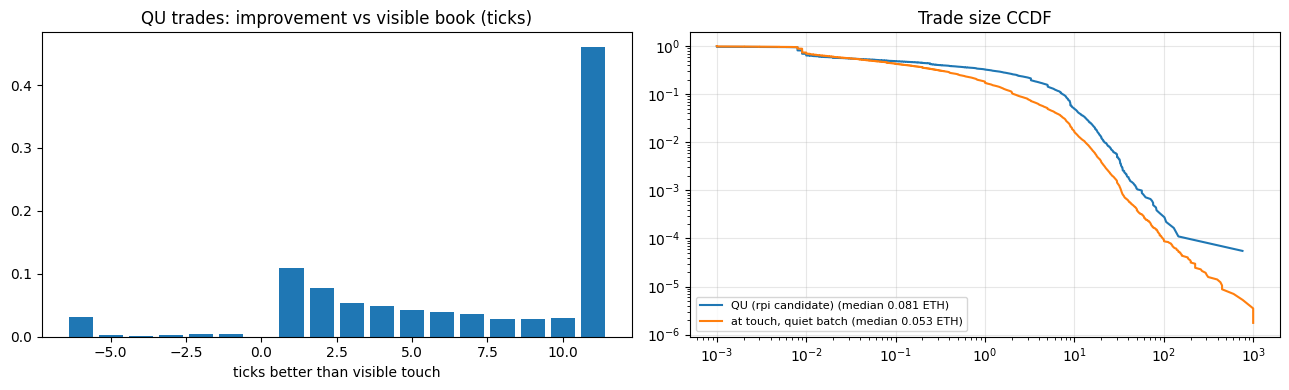

In [5]:
if len(sizes):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].bar(hist.index, hist / hist.sum()); ax[0].set_title('QU trades: improvement vs visible book (ticks)'); ax[0].set_xlabel('ticks better than visible touch')
    for gname, gdf in sizes.groupby('group'):
        q = np.sort(gdf.qty.to_numpy()); ax[1].loglog(q, 1 - np.arange(len(q)) / len(q), label=f'{gname} (median {np.median(q):.3f} ETH)')
    ax[1].set_title('Trade size CCDF'); ax[1].legend(fontsize=8); ax[1].grid(alpha=.3)
    plt.tight_layout(); fig.savefig(REP / '04_rpi_test.png', dpi=110); plt.show()

## 2 · Feature sanity (distributions only)
Coverage, validity and plain distributions per clock. There is **no** look at returns or targets here: relationships with future prices are only examined after the protocol is frozen (notebook 05 onwards).

In [6]:
display(fst.style.format({'valid_ex': '{:.2%}', 'valid_rx': '{:.2%}', 'empty_bins_ex': '{:.2%}', 'rpi_share': '{:.3%}', 'rx_age_p99_ms': '{:.0f}', 'bins': '{:,.0f}', 'rpi_trades': '{:,.0f}'}))
g = ma_lib.derive_features(pd.read_parquet(FEA / 'ex' / f'feat_ex_{DATES[0]}.parquet'))
g = g[g.valid]
cols = ['ofi1', 'ofi2', 'ofi5', 'ofi_int10', 'ti', 'ti_x', 'signed_orders', 'qi1', 'qi5', 'wmid_dev', 'spread', 'd10b', 'd10a', 'rv_halfticks2', 'n_batches', 'n_trades']
desc = g[cols].describe(percentiles=[.01, .5, .99]).T
desc['zero_share'] = (g[cols] == 0).mean()
print(f'feature distributions on {DATES[0]} (valid exchange-clock bins, 100 ms; flows in lots of 0.001 ETH):'); display(desc.round(3))
gr0 = pd.read_parquet(FEA / 'rx' / f'feat_rx_{DATES[0]}.parquet')
both = g[['t_end', 'mid2']].merge(ma_lib.derive_features(gr0)[['t_end', 'mid2']], on='t_end', suffixes=('_ex', '_rx'))
print(f"received clock lags exchange clock: mid differs in {(both.mid2_ex != both.mid2_rx).mean():.1%} of bins at the same wall time (expected: feed latency ~127 ms ≈ 1–2 bins)")

,bins,valid_ex,valid_rx,empty_bins_ex,rx_age_p99_ms,rpi_trades,rpi_share
date,,,,,,,
2026-09-07,"864,000",99.82%,99.82%,0.16%,32,975,0.027%
2026-09-08,"864,000",99.02%,99.02%,0.01%,35,"1,477",0.035%
2026-09-09,"864,000",99.71%,99.64%,0.01%,46,"1,165",0.025%
2026-09-10,"864,000",97.86%,97.83%,0.01%,46,"1,225",0.027%
2026-09-11,"864,000",99.35%,99.31%,0.03%,44,"10,125",0.128%
2026-09-12,"864,000",95.88%,95.87%,0.01%,42,332,0.019%
2026-09-13,"864,000",92.56%,92.55%,0.02%,44,"1,119",0.041%
2026-09-14,"864,000",98.82%,98.72%,0.72%,118,"1,716",0.030%


feature distributions on 2026-09-07 (valid exchange-clock bins, 100 ms; flows in lots of 0.001 ETH):


,count,mean,std,min,1%,50%,99%,max,zero_share
ofi1,862450.0,383.198,94668.066,-5538658.00,-323142.260,0.000,325395.140,7.266681e+06,0.110
ofi2,862450.0,-38.301,27157.825,-3417568.00,-16111.080,0.000,16816.530,9.744010e+06,0.746
ofi5,862450.0,-41.990,21104.138,-4710082.00,-11803.510,0.000,11818.530,5.586604e+06,0.775
ofi_int10,862450.0,68.642,172995.825,-10894926.00,-455217.300,0.000,464215.890,1.104313e+07,0.069
ti,862450.0,-131.297,33352.931,-9448632.00,-25320.510,0.000,22928.040,7.884318e+06,0.674
ti_x,862450.0,-130.108,33313.244,-9448632.00,-25312.510,0.000,22934.080,7.884318e+06,0.674
signed_orders,862450.0,0.017,1.482,-64.00,-4.000,0.000,4.000,5.000000e+01,0.699
qi1,862450.0,0.038,0.605,-1.00,-0.980,0.059,0.983,1.000000e+00,0.000
qi5,862450.0,0.034,0.599,-1.00,-0.976,0.052,0.978,1.000000e+00,0.000
wmid_dev,862450.0,0.019,0.316,-16.59,-0.490,0.030,0.491,3.986500e+01,0.000


received clock lags exchange clock: mid differs in 4.8% of bins at the same wall time (expected: feed latency ~127 ms ≈ 1–2 bins)


## 3 · Protocol freeze
Everything below is decided **now**, before any relationship between features and future prices has been looked at. The file is hashed. Later notebooks call `ma_lib.load_protocol(OUT_DIR)`, which raises an error if a single character changed. If the protocol already exists, this cell refuses to overwrite it with different content.

In [7]:
protocol = {
  'project': 'Microstructure Alpha — Binance USD-M ETHUSDT perpetual, 2026-09-07..14',
  'frozen_after': 'notebook 04 (features built; no target relationships examined)',
  'stage0': {'verdict': stage0, 'rpi_test': {k: bool(v) for k, v in rpi_tests.items()},
             'limitations': ['intra-batch prints in fast markets (~27 ms batching)', 'RPI liquidity absent from the standard depth stream',
                             'feed latency median ~127 ms (non-colocated capture)', 'one instrument, 8 days']},
  'data_split': {'development': ALL_DATES[0:5], 'selection': [ALL_DATES[5]], 'test': ALL_DATES[6:8],
                 'walk_forward': 'expanding by day within development: train D1 -> validate D2, train D1-2 -> validate D3, ..., train D1-4 -> validate D5',
                 'selection_rule': 'every modeling and strategy choice is frozen after evaluating on the selection day',
                 'test_rule': 'test days are evaluated exactly once, in the robustness notebook, after all choices are frozen',
                 'secondary': 'rolling walk-forward over all 8 days reported for transparency only, never used for choices',
                 'calendar_notes': '2026-09-07 is US Labor Day; 2026-09-12/13 are a weekend (selection day + first test day)'},
  'purge_embargo': {'rule': 'drop samples within max(prediction horizon, feature lookback) of every train/validation boundary',
                    'embargo_minutes': 10, 'max_feature_lookback_minutes': 5, 'max_horizon_seconds': 120},
  'grid': {'bin_ms': BIN_MS, 'regression_bucket_s': 1, 'clocks': {'research': 'exchange time (transaction_time / trade time)',
           'trading': 'received time + order-send latency'}, 'latency_grid_ms': [0, 50, 130, 250]},
  'target': {'definition': 'Δmid_h = mid(t+h) − mid(t), t = decision time (bin end)', 'units': ['ticks (half-tick resolution)', 'basis points'],
             'horizons_s': [0.1, 0.25, 0.5, 1, 5, 30, 120], 'excluded_horizons': '10 ms (below the ~27 ms batching)'},
  'exclusions': {'always': ['invalid_book windows (valid == 0)', 'resync_gap windows', 'grid bins with valid == False'],
                 'received_clock': [f'feed latency > {LAT_BAD_MS} ms', f'state age > {STALE_MS} ms'],
                 'robustness_only': ['RPI-candidate trades (ti_x vs ti)', 'fast batches (|Δmid| >= 4 ticks)', 'hours containing a resync']},
  'features': {'flows': ma_lib.FLOW_COLS, 'states': ma_lib.STATE_COLS,
               'derived': ['mid2', 'spread', 'qi1', 'qi5', 'wmid_dev', 'ti', 'ti_x', 'ofi_int10', 'signed_orders'],
               'fitted_on_development_only': ['integrated OFI (PCA across levels)', 'Stoikov microprice', 'standardisation constants', 'depth normaliser D̄'],
               'transforms': {'ewma_half_lives_s': [0.5, 1, 5, 30, 120], 'max_lag_s': 300}},
  'hypotheses': {
    'H1': 'Contemporaneous 1 s buckets: ΔP = α + β·OFI1 with β > 0 (HAC t > 1.96 on every development day); OFI1 R² exceeds trade-imbalance R² on ≥ 4 of 5 development days.',
    'H2': 'β ∝ 1/D: across deciles of bucket-mean touch depth, log β vs log D̄ slope has a 95% CI that excludes 0; whether it includes −1 is reported (open-snapshot version shown as the attenuated control).',
    'H3': 'Lagged OFI predicts ΔP_h out of sample (walk-forward) above the shuffle null at 5% after Romano–Wolf across the horizon grid; the horizon of peak OOS R² is reported.',
    'H4': 'Event-time sampling (mid-change and volume clocks) beats clock time at matched sample counts: Diebold–Mariano p < 0.05.',
    'H5': 'Multi-level or integrated OFI beats level-1 OFI and the microprice out of sample: DM p < 0.05; a level is kept only if its marginal OOS R² gain has a 95% block-bootstrap CI above 0.',
    'H6': 'Taker-order signs show long memory (power-law ACF exponent γ < 1, 95% CI) and impact is transient (fitted propagator kernel decays).',
    'H7': 'Hawkes intensity features add OOS R² beyond OFI: DM p < 0.05.'},
  'inference': {'hac': 'Newey–West, lags = ceil(h / bucket) + 5', 'bootstrap': {'type': 'moving block', 'block_minutes': 5, 'reps': 1000},
                'model_comparison': 'Diebold–Mariano on squared errors', 'multiple_testing': 'Romano–Wolf stepdown over horizon × model grid, 1000 reps',
                'sharpe': 'deflated Sharpe ratio for the number of configurations tried', 'alpha': 0.05, 'seed': 7},
  'costs': {'fee_grid_bp': {'maker': [-0.5, 0.0, 1.0, 2.0], 'taker': [2.5, 4.0, 5.0]},
            'fee_rule': 'every strategy result is reported across the full pre-registered fee grid; the headline row uses the account tier entered in notebook 07 (must be a grid point)',
            'tick_size_usdt': 0.01, 'lot_size_eth': 0.001, 'funding_settlements_utc': ['00:00', '08:00', '16:00']},
  'strategy': {'track_A': 'parent orders (e.g. 50 ETH over 10 min) at random start times/sides; TWAP vs OFI-timed children; metric: implementation shortfall vs arrival mid (bp) with block-bootstrap CI',
               'track_B': 'touch quoting skewed by the forecast; queue position from real fill sizes; cancels ahead bounded pessimistic (none) / optimistic (pro-rata); RPI caveat: visible-book makers cannot compete for RPI-matched retail flow, so maker fills are an upper bound',
               'track_C': 'directional taker only where |prediction| > round-trip cost',
               'kill_criteria': {'max_drawdown': '> 3× the daily PnL standard deviation on the selection day',
                                 'adverse_selection': '5 s markout worse than the spread captured',
                                 'latency': 'alpha half-life shorter than the send latency'}},
}
pfile = PRO / 'protocol.json'
if pfile.exists():
    old = ma_lib.load_protocol(OUT_DIR)
    if json.dumps(old, sort_keys=True, default=str) != json.dumps(json.loads(json.dumps(protocol, default=str)), sort_keys=True, default=str):
        raise RuntimeError('a different protocol is already frozen; refusing to overwrite. Delete protocol/ only if you deliberately restart the study.')
    print('protocol already frozen with identical content')
h = ma_lib.write_protocol(pfile, protocol)
assert ma_lib.load_protocol(OUT_DIR)['data_split']['selection'] == [ALL_DATES[5]]
print('protocol frozen:', pfile, '\nsha256:', h)

protocol frozen: C:\microalpha_proj\microoutput\protocol\protocol.json 
sha256: 0224381a70665d880a38c72f35f2b250fa3c97b7281b56e817d71372b22234af


In [8]:
lines = ['# 04 · RPI test, features, protocol: summary', '',
         f"QU trades (unexplained, |Δmid| ≤ 1 tick): {int(P.qu):,}; better than visible {P.qu_wrong_or_inside/P.qu:.1%}; "
         f"1–3 tick improvement {P.qu_impr_1_3/P.qu:.1%}; covering queue drop {P.qu_drop_covers/P.qu:.1%} (control {P.ctl_drop_covers/P.ctl:.1%}); "
         f"single fill {P.qu_single/P.qu:.1%} (control {P.ctl_single/P.ctl:.1%})"]
lines += [('PASS ' if v else 'FAIL ') + k for k, v in rpi_tests.items()] + [f'STAGE 0: {stage0}', '',
          f"feature grid: {int(fst.bins.sum()):,} bins of {BIN_MS} ms per clock; valid ex {fst.valid_ex.mean():.2%}, rx {fst.valid_rx.mean():.2%}",
          f"rpi-flagged trades: {int(fst.rpi_trades.sum()):,} ({fst.rpi_trades.sum()/ (fst.rpi_trades.sum()/fst.rpi_share).sum():.3%})",
          f"protocol sha256: {h}"]
(REP / '04_summary.md').write_text('\n'.join(lines), encoding='utf-8'); print('\n'.join(lines))
print('\nSend me: reports/04_summary.md, 04_rpi_test.csv, 04_feature_days.csv, 04_rpi_test.png, protocol/protocol.json')

# 04 · RPI test, features, protocol: summary

QU trades (unexplained, |Δmid| ≤ 1 tick): 18,134; better than visible 95.3%; 1–3 tick improvement 24.0%; covering queue drop 82.3% (control 79.7%); single fill 5.9% (control 32.3%)
PASS R1  ≥ 70% better than the visible book (pooled and ≥ 6 days)
FAIL R2  ≥ 80% improve by 1–3 ticks (pooled and ≥ 6 days)
FAIL R3  ≤ 20% with a covering visible queue drop (pooled and ≥ 6 days)
STAGE 0: NOT PASSED

feature grid: 6,912,000 bins of 100 ms per clock; valid ex 97.88%, rx 97.85%
rpi-flagged trades: 18,134 (0.004%)
protocol sha256: 0224381a70665d880a38c72f35f2b250fa3c97b7281b56e817d71372b22234af

Send me: reports/04_summary.md, 04_rpi_test.csv, 04_feature_days.csv, 04_rpi_test.png, protocol/protocol.json
